# Integrated Intelligent Systems: Tutorial 2 - Body Motion Problem (Action Designator & URDF) (3 Pts)

This notebook introduces the body motion problem central to designing and implementing Cognition-Enabled Robot Agents.

## Part 1: Action Designator (E1–E6) (1.5 Pt)

**Title:** The Body Motion Problem: Serving Eva a Drink & Breakfast

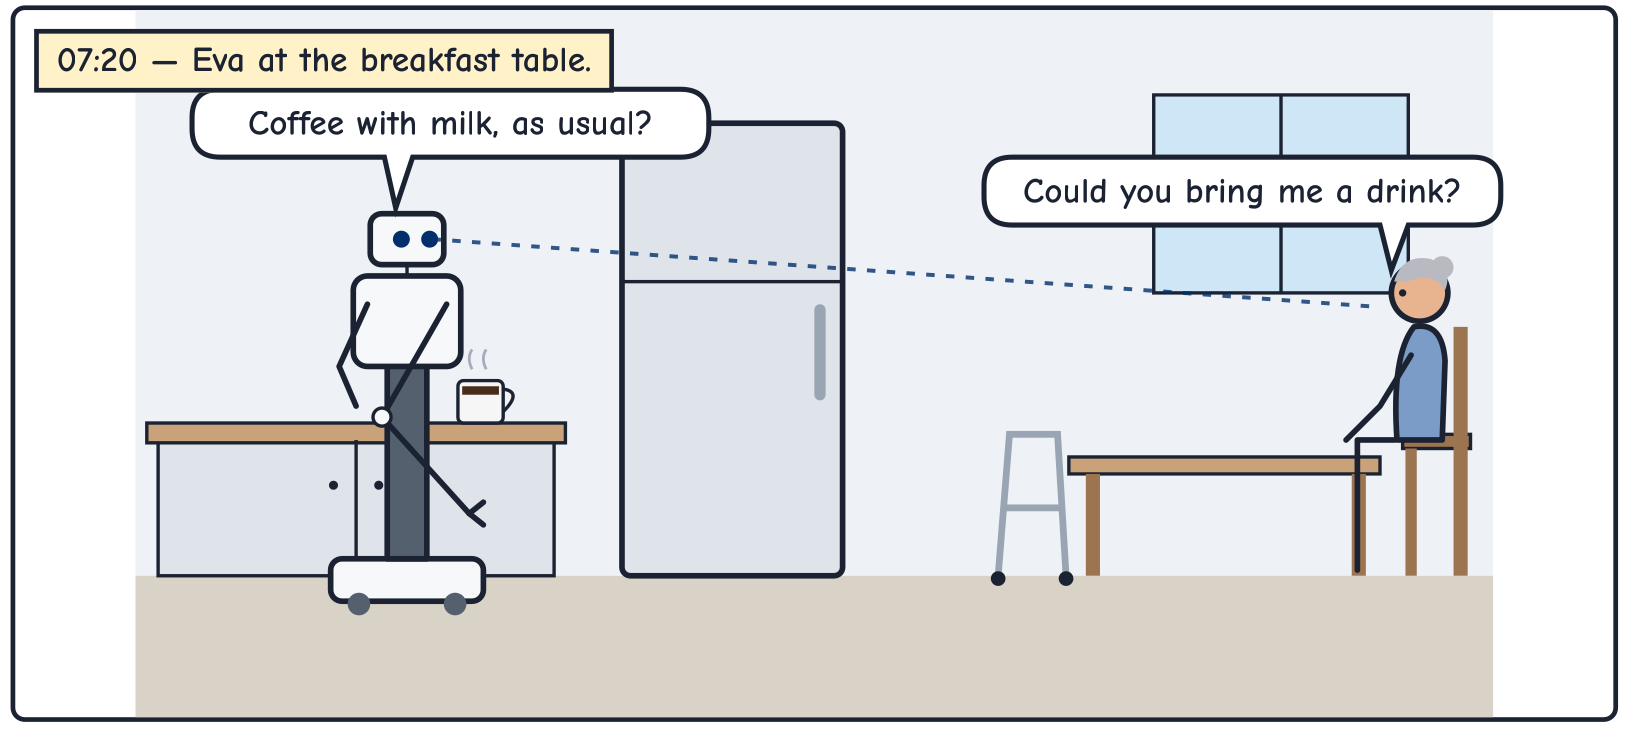

### Scenario Background
Eva says: "Serve me a drink."

The kitchen contains two milk cartons in the fridge door:
- **Carton A:** Opened whole milk.
- **Carton B:** Unopened oat drink.

Eva's usual mug already contains hot black coffee on the counter.

A wet surface on Carton A causes slip during a low test lift, requiring a grasp adaptation before pouring.

---

### Multi-Question Student Task Sheet (0.25 Pt x 6)

1. **E1 · The Gap & Whole-Course Judgment**
   - Eva says "Serve me a drink." A video shows a robot executing a smooth trajectory, placing the mug on the table, but a photograph reveals milk spilled across the counter and an open fridge left behind. Explain why this nominal end-state success does **not** constitute a solution to the Body Motion Problem, and specify two whole-course constraints that were violated.

2. **E2 · Constrained Action Designator & Grounding**

    - Distinguish interpretation, inferred means, and grounded objects for this episode by filling out the three missing slots in the schematic action designator:
    
    - **Working Interpretation:** `(:type serving) (:recipient Eva) (:substance ________)`
    - **Inferred Function/Means:** `(:vessel-role ________)`
    - **Grounded Physical Object:** `(:object ________)`

3. **E3 · The Commitment Decision & Asymmetric Failure Costs**

    - During the retrieval step, the robot faces a choice between a **5 mm test lift near the shelf** or a **high carry directly to the counter**. State the predicted effect, the cost of failure, and the single piece of evidence that justifies choosing the low test lift before committing to the carry.

4. **E4 · Causal Prediction across Material Variants**

    - Compare pouring milk into coffee versus pancake batter into a pan. Formulate the stopping rule for each liquid using `(:stop-when ...)`, and explain how material dynamics alter when the robot must command the wrist to tilt back.

5. **E5 · System Decomposition & The Reasoning Loop**

    - Trace the carton slip event through the seven-stage reasoning loop: **Infer → Ground → Predict → Decide → Regulate → Detect & Revise → Verify**. State precisely which step was triggered when downward motion was observed during the 5 mm lift, and how the action designator was developed in response.

6. **E6 · Conceptual Ablation & Evidence of Competence**

    - Perform an ablation experiment. Suppose we remove the **"Check before commitment"** capability and replace it with a fixed default high-side-pinch lift. Predict a specific kitchen environment variant where this ablated system fails, and explain why single-run execution success differs from evidence of general competence across task variants.

### Answers Part 1(E1-E6):
### E1 · The Gap & Whole-Course Judgment

**Why end-state success is not a solution.** The Body Motion Problem asks for a *whole motion course*: the body movements must realise the intended action **and** respect the physical, material and environmental constraints during the entire execution, not only at the final pose. A smooth trajectory that ends with the mug on the table is a *necessary* snapshot, but the photograph shows the task goal ("Eva gets a drink she can use") was not achieved and that the world was damaged along the way. The video evaluates the end-effector path, the photo evaluates the consequences. A solution must be judged by both.

**Two violated whole-course constraints**
1. **Material / containment constraint** – the liquid must stay in its container. Orientation (tilt) and acceleration limits of the wrist during pouring/carrying were not enforced and the stopping condition (`stop-when` fill level / flow) was missing, so milk spilled onto the counter.
2. **Side-effect / world-restoration constraint** – the environment must be left in an acceptable state: the fridge door was opened for retrieval and never closed (cold chain, safety, a later collision hazard). A complete plan includes the closing/cleanup motion and the appropriate handling of the carton.

### E2 · Constrained Action Designator & Grounding

"Serve me a drink" is underspecified. Eva's mug already holds hot black coffee, and
two cartons are available, so the drink is served by adding milk to the coffee.

| Level | Slot | Filled value |
| --- | --- | --- |
| Working interpretation | `(:substance ...)` | `(milk :into coffee)` |
| Inferred function / means | `(:vessel-role ...)` | `pouring-source` |
| Grounded physical object | `(:object ...)` | `carton-A` |

```lisp
(an action
  (:type serving)
  (:recipient Eva)
  (:substance (milk :into coffee))   ; interpretation: what the request means
  (:vessel-role pouring-source)      ; inferred means: something that holds and pours milk
  (:object carton-A))                ; grounded: opened whole-milk carton in the fridge door
```

- **Interpretation** = what is wanted: coffee with milk for Eva.
- **Inferred means** = the abstract role an object must play: a container the milk can be poured from. Eva's mug is the receiving target and is already in place.
- **Grounded object** = the concrete perceived object filling that role. Carton B (unopened oat drink) is the wrong substance and is unopened, so perception grounds the role to carton A.

### Answer E3 · The Commitment Decision & Asymmetric Failure Costs

**Chosen action:** 5 mm test lift near the shelf *before* committing to the carry.

- **Predicted effect:** the carton rises ≈5 mm with the gripper, with **no relative downward motion** between carton and fingers (contact force/load stays steady, carton pose stays rigid w.r.t. the gripper).
- **Cost of failure (asymmetric):**
  - *Test lift fails:* carton slips a few mm and drops back onto the shelf → negligible, cheap, reversible; just re-grasp.
  - *High carry fails:* carton falls from height mid-motion → milk spilled, carton/mug damaged, floor and counter contaminated, possibly a person nearby affected → expensive, irreversible.
  - Since a cheap, informative probe exists and the error cost of committing blindly is much higher, probing first is rational.
- **Single piece of evidence:** the **wet surface on carton A** (visual/tactile cue) → the friction coefficient is low and *uncertain*, so the grasp's holding capacity cannot be assumed; a 5 mm lift tests it directly.

### E4 · Causal Prediction across Material Variants

```lisp
;; milk into coffee
(:stop-when (>= predicted-final-milk-volume 30 mL))
;; pancake batter into a pan
(:stop-when (>= predicted-settled-disc-diameter 12 cm))
```

- **Milk (low viscosity):** it flows fast and stops almost as soon as the wrist tilts back, but some milk is still in the spout and in flight. The tilt-back is therefore commanded slightly before the poured volume reaches 30 mL, so the final amount lands on target. Where the milk lands matters little, because it mixes into the coffee.
- **Batter (thick, viscous):** it keeps flowing after the tilt-back and keeps spreading outward after it lands. The rule must use the predicted settled diameter, not the diameter visible now, so the wrist tilts back well before the disc looks 12 cm wide. Landing position and post-flow spread both matter here.
- **Result:** the stopping rule is on the predicted final state, and the tilt-back time depends on the material's dynamics.

### E5 · System Decomposition & The Reasoning Loop

Trace of the carton-slip episode through the seven stages:

| Stage | What happens in this episode |
|---|---|
| 1. **Infer** | "Serve me a drink" is interpreted as: add milk to the coffee in Eva's mug and serve it. |
| 2. **Ground** | Perception identifies carton A (opened whole milk) as the pouring source, rejecting carton B (unopened oat drink), and locates Eva's mug on the counter. |
| 3. **Predict** | A side pinch on carton A is predicted to hold, but the wet surface makes friction uncertain, so the holding capacity is not guaranteed. |
| 4. **Decide** | Because a high carry costs much more to fail than a low probe, the robot commits to a 5 mm test lift near the shelf before the carry. |
| 5. **Regulate** | The lift is executed with grip-force and motion control, while carton pose and contact are monitored. |
| 6. **Detect & Revise** | **Triggered here.** Downward motion of the carton relative to the fingers contradicts the prediction. The belief "side pinch is reliable" is revised, the carton is set down, and the designator is updated, e.g. `(:grasp bottom-support)` for lifting with extra grip force, and a changed grasp for pouring because bottom support blocks tilting. |
| 7. **Verify** | A new test lift confirms there is no slip. The carry and pour are then checked against the constraints: no spill, 30 mL target, and the fridge closed afterwards. |

**Precisely:** the observed downward motion during the 5 mm lift triggers **Detect & Revise**. The designator develops from "side-pinch lift and carry" to a revised grasp, and verification confirms the new grasp before the carry is committed.

### E6 · Conceptual Ablation & Evidence of Competence

**Ablation:** remove "check before commitment" → the robot always executes a fixed default *high side-pinch lift and carry*.

**Variant where it fails:** the same kitchen but carton A is *wet* (as in this episode), or a nearly-full 1 L carton / glass bottle with a slippery surface, or the carton sits on a narrow fridge-door shelf where a high side pinch is blocked. Without a probe, the robot cannot sense the low friction before moving: the carton slips mid-carry from height → milk spilled, task failure, mess and possible hazard. (In the dry, half-empty variant the same fixed policy would succeed, hiding the weakness.)

**Why one successful run ≠ competence**
- A single success samples only one point of the variation space (dry, light, one pose, one lighting); it could be luck or coincidence between the fixed default and the conditions.
- Competence means *reliably* achieving the goal across variation (surface wet/dry, mass, container type, positions, material) and **failing safely** when conditions are bad. This requires systematic variant testing, reporting success rate, failure modes and recovery behaviour, and showing that the capability (check/predict/revise) is what explains success – exactly what the ablation exposes.

## Part 2: Kino-Dynamic Modeling of Robot World System with URDF (1.5 Pt)

**Title:**  Designing and Implementing the kino-dynamic model of the robot world system with URDF

### 2.1  Theoretical Background

In [1]:
from IPython.display import display, HTML,IFrame
display(IFrame('urdf_background.html', width=1000, height=2000))

## 2.2  Hands-on: Model your own robot world system according to specifications below (1.5 Pt)

In [2]:
from IPython.display import display, HTML,IFrame
display(IFrame('urdf_handon.html', width=1000, height=2000))

### Answers Part 2:
### 2.1 Theoretical Background

**URDF** The Unified Robot Description Format is an XML description of the
physical structure of a robot (links) and of the connections between them (joints). It
acts as the mathematical model of the robot body, covering geometry, appearance,
kinematics, dynamics and statics. A URDF file can be loaded in RViz, Gazebo, MuJoCo,
Unreal Engine or PyBullet, and it is used in the design phase (model validation),
the development phase (part of the program) and the execution phase (verification
and debugging).

**Links** are the physical objects (robot parts, but also furniture or appliances in an
environment). Each link has three parameter groups:
- *Visual*: appearance and shape.
- *Collision*: a simplified shape used for collision detection, which reduces computation.
- *Inertial*: mass and inertia, i.e. how the link behaves under physical forces.

**Joints** connect a parent link to a child link and define their relative motion through
a *type*, an *axis* (a 3D direction vector) and *limits* (position range, velocity, effort).
- *Revolute* joints give rotary motion, e.g. a fridge door hinge.
- *Prismatic* joints give linear motion, e.g. a drawer.
(Fixed and continuous joints are used as well.)

**Modularity and parameterization (Xacro).** Instead of one monolithic file, the model is
composed from separate files for components such as a base, an arm or a gripper, joined
in a top-level file with `<xacro:include>`. Dimensions, masses and joint limits are not
hard-coded but written as `${param_name}`, and macros let one component definition be
instantiated several times with different values. This makes the model readable,
reusable and easy to reconfigure, e.g. for a different counter height or reach.

**Relevance here.** The drink-serving robot is built in this way: base, arm and gripper
files are included in `robot.xacro`, and the fridge shelf, carton, counter and mug are
modelled as links so the whole robot world system can be checked in one model.

### 2.2 Hands-on: model and implementation notes

**Design.** A mobile manipulator "domestic assistant", split into four Xacro
files in `Assignment2/` (composition), with all dimensions as properties
(parameterization). `mini_xacro.py` is a fallback expander; `robot.urdf` is the generated model.

| File | Contents | Key parameters |
|---|---|---|
| `base.xacro` | Cylindrical base on virtual planar joints (`base_x`, `base_y` prismatic, `base_yaw` continuous) so the robot can drive from fridge to counter | `base_radius`=0.25, `base_height`=0.30 |
| `arm.xacro` | 3-DOF arm: prismatic `lift_joint` (0–0.40 m), revolute `shoulder_joint` and `elbow_joint` (axis −y) | `link1_length`=0.35, `link2_length`=0.30, `lift_stroke`=0.40 |
| `gripper.xacro` | `wrist_roll_joint` (tilts the carton for pouring), palm, two prismatic fingers, `tool_frame` | `gripper_span`=0.14 |
| `robot.xacro` | Includes the three files, defines environment parameters, assembles the robot and a static kitchen (fridge shelf, milk carton, counter, Eva's mug) | counter 0.90, shelf 0.40, carton 0.10x0.10x0.20, mug r=0.08 h=0.12, reach 0.55 |

**Gripper check.** Inner finger gap goes from 0.02 m (closed) to 0.14 m (open).
This is greater than the 0.10 m carton width, leaving 0.02 m clearance per side.

**Reach check (end-effector = `tool_frame`, 0.12 m beyond link2).**
The shoulder is at 0.40 + lift m (0.40–0.80 m). With the gripper kept horizontal,
the wrist is at (target distance − 0.12) m from the shoulder, so
cos(theta1) = (wrist distance − link2)/link1, tool height = shoulder height + link1·sin(theta1).
- Fridge shelf (carton at 0.55 m): lift 0.325 m, shoulder −68.2°, elbow +68.2° → tool at **0.40 m**.
- Pouring (mug at 0.63 m): lift 0.32 m, shoulder +53.1°, elbow −53.1° → tool at **1.00 m**.
The reachable tool height range with a horizontal gripper is about 0.08–1.125 m,
covering both targets within all joint limits.

**Parameter flexibility.** `elbow_joint` is placed at `link1_length` and the
gripper attaches at `link2_length`, so changing `link1_length` (e.g. 0.35 → 0.45)
and regenerating moves the elbow, link2 and gripper consistently; no transform breaks.

**Modular structure.** `robot.xacro` includes `base.xacro`, `arm.xacro` and
`gripper.xacro`, then instantiates `base`, `arm` (mounted at `base_height`)
and `gripper` (attached to `link2`).

**Limitations.** This is a kinematic model. It does not include collision-free
planning, grasp stability or pouring dynamics. The wrist roll counts as an
end-effector joint, so the arm proper is 3-DOF. At the 1.0 m pouring pose the
gripper sits close to the mug rim (mug top at 1.02 m), so the carton would be grasped
offset from the mug centre or lifted slightly higher (up to ~1.1 m is reachable).

**Verification.** `robot.urdf` is generated from `robot.xacro` with
`python -c "import mini_xacro; open('robot.urdf','w').write(mini_xacro.process('robot.xacro'))"`
(or `xacro robot.xacro > robot.urdf` with ROS) and can be loaded in a URDF viewer.
Moving the joints to the two poses above (lift, shoulder and elbow values as listed)
places the tool frame at about 0.40 m (fridge shelf) and 1.00 m (pouring height).